# NeuroVal-3D — Phase 2 on Kaggle

End-to-end demo of the validator stack on real radiology data, plus Stage 1 preprocessing on one BraTS 2020 volume.

**What this notebook does:**
1. Clones the project from your GitHub mirror
2. Downloads 369 TextBraTS reports (HuggingFace, MIT)
3. Downloads 1,007 RadGenome-Brain MRI reports (HuggingFace, research-only)
4. Runs the held-out perturbation benchmark on **TextBraTS**
5. Runs the held-out perturbation benchmark on **RadGenome-Brain MRI**
6. Runs Stage 1 preprocessing on one BraTS 2020 volume from the attached Kaggle dataset
7. Plots the headline AUROC bar chart vs BioClinicalBERT and RaTEScore-lite

Expected wall-clock with T4 GPU: ~20 minutes. CPU only: ~1.5 hours.


## Prerequisites

**Kaggle setup before running:**
1. Settings (right rail) → **Internet: ON**
2. Settings → **Accelerator: GPU T4 ×2** (or P100, either works)
3. **Add Data** (right rail) → search **`brats20-dataset-training-validation`** by user **awsaf49** → Add
4. Edit `GITHUB_URL` in the cell below to point to your fork/clone of the repo

**Direct dataset link:**
https://www.kaggle.com/datasets/awsaf49/brats20-dataset-training-validation


In [1]:
# Project lives at vicky-16032005/neuroval3d (set 2026-04-30)
GITHUB_URL = "https://github.com/vicky-16032005/neuroval3d.git"

import os, subprocess, sys
PROJECT_DIR = "/kaggle/working/neuroval3d"

# 1. Heavy installs Kaggle doesn't ship by default
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "monai>=1.3", "nibabel>=5.2", "SimpleITK>=2.3", "python-dotenv"], check=True)

# 2. Clone the project
if not os.path.isdir(PROJECT_DIR):
    subprocess.run(["git", "clone", GITHUB_URL, PROJECT_DIR], check=True)
os.chdir(PROJECT_DIR)

# 3. Install our package + extras (data) for huggingface_hub etc.
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[data,eval]"], check=True)

print("Project at:", PROJECT_DIR)
print(os.listdir(PROJECT_DIR))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 31.9 MB/s eta 0:00:00


Cloning into '/kaggle/working/neuroval3d'...
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.25.1 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2026.2.0 which is incompatible.


Project at: /kaggle/working/neuroval3d
['context v1', 'tests', 'pyproject.toml', 'configs', 'notebooks', 'scripts', 'README.md', 'Makefile', 'docs', '.gitignore', 'LICENSE', 'outputs', 'uv.lock', 'src', '.git', 'data', 'RUN_LOG.md']


In [2]:
# Sanity check imports + GPU
import sys, torch, importlib
print(f"python: {sys.version.split()[0]}")
print(f"torch:  {torch.__version__}, cuda available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"  device: {torch.cuda.get_device_name(0)}, vram: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

# Some Kaggle environments resolve `neuroval3d` to an empty namespace package despite
# the editable install succeeding. Force-prepend our src/ to sys.path and drop any
# stale module cache before the first real import.
_PROJECT_SRC = "/kaggle/working/neuroval3d/src"
if _PROJECT_SRC not in sys.path:
    sys.path.insert(0, _PROJECT_SRC)
for _m in list(sys.modules):
    if _m == "neuroval3d" or _m.startswith("neuroval3d."):
        del sys.modules[_m]

import neuroval3d
print(f"neuroval3d: v{getattr(neuroval3d, '__version__', '?')} from {neuroval3d.__file__}")


python: 3.12.12
torch:  2.10.0+cu128, cuda available: True
  device: Tesla T4, vram: 15.6 GB
neuroval3d: v0.0.1 from /kaggle/working/neuroval3d/src/neuroval3d/__init__.py


## 1 · Download real radiology reports from HuggingFace

TextBraTS (369) and RadGenome-Brain MRI (1,007) — both fully public, no auth needed.


In [3]:
# This pulls all 369 TextBraTS reports into data/raw/TextBraTS/reports/
import subprocess, sys
subprocess.run([sys.executable, "scripts/download_textbrats_reports.py"], check=True)


Listing files in Jupitern52/TextBraTS...
Found 369 report files.
  ...50 downloaded
  ...100 downloaded
  ...150 downloaded
  ...200 downloaded
  ...250 downloaded
  ...300 downloaded
  ...350 downloaded

Done: 369 downloaded, 0 already-present, 0 failed.
Total reports under data/raw/TextBraTS/reports: 369


CompletedProcess(args=['/usr/bin/python3', 'scripts/download_textbrats_reports.py'], returncode=0)

In [4]:
# This pulls 16 JSON files (5 disease subsets × 3 sections + split) into data/raw/RadGenome-BrainMRI/
import subprocess, sys
subprocess.run([sys.executable, "scripts/download_radgenome_reports.py"], check=True)


Found 16 JSON files in JiayuLei/RadGenome-Brain_MRI.
  BraTS_GLI/global_finding.json: 117,506 bytes
  BraTS_GLI/impression.json: 106,395 bytes
  BraTS_GLI/modal_wise_finding.json: 258,540 bytes
  BraTS_MEN/global_finding.json: 100,155 bytes
  BraTS_MEN/impression.json: 49,156 bytes
  BraTS_MEN/modal_wise_finding.json: 239,090 bytes
  BraTS_MET/global_finding.json: 114,422 bytes
  BraTS_MET/impression.json: 62,834 bytes
  BraTS_MET/modal_wise_finding.json: 224,429 bytes
  ISLES22/global_finding.json: 61,851 bytes
  ISLES22/impression.json: 81,228 bytes
  ISLES22/modal_wise_finding.json: 57,020 bytes
  WMH/global_finding.json: 15,260 bytes
  WMH/impression.json: 14,040 bytes
  WMH/modal_wise_finding.json: 12,166 bytes
  train_val_test_split.json: 122,312 bytes

Done: 16/16 files under data/raw/RadGenome-BrainMRI


CompletedProcess(args=['/usr/bin/python3', 'scripts/download_radgenome_reports.py'], returncode=0)

## 2 · Held-out benchmark on **TextBraTS** (369 reports)

70/30 split by `original_id` — fusion is trained on 258 base reports, evaluated on 111 unseen ones.


In [5]:
from neuroval3d.evaluation import run_benchmark
from neuroval3d.data import textbrats_reports_only

tb_reports = textbrats_reports_only()
print(f"Loaded {len(tb_reports)} TextBraTS reports.")

result_tb = run_benchmark(
    reports=tb_reports,
    use_synthetic=False,
    n_samples=len(tb_reports),
    train_frac=0.7,
)
print(result_tb.summary_table())


Loaded 369 TextBraTS reports.


[04/30/26 16:16:42] INFO     Building perturbation set on 369 reports (n_per_report=4)...

                    INFO     Semantic validator on device: cuda:0

scoring:   0%|          | 0/1829 [00:00<?, ?rec/s]

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

...

BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

[04/30/26 16:17:48] INFO     Held-out split: 1278 train rows, 551 test rows (by 258/111 base reports)

                    INFO     Benchmark complete; held-out AUROC fusion = 0.9962 (train AUROC = 0.9990)

| Validator | Held-out Test AUROC | Train AUROC | laterality | negation | region | vasari_flip |
|-----------|---------------|-----------|----------|----------|----------|----------|
| fusion | 0.9962 | 0.9990 | 0.9955 | 1.0000 | 0.9967 | 1.0000 |
| lesion_type | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 |
| lexical | 0.4218 | 0.4547 | 0.3156 | 1.0000 | 0.5148 | 0.8348 |
| modality | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 |
| negation | 0.0498 | 0.0413 | 0.0495 | 0.1126 | 0.0495 | 0.0495 |
| numeric | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 |
| ratescore_lite (baseline) | 0.0099 | 0.0212 | 0.0080 | 0.1734 | 0.0098 | 0.0375 |
| semantic | 0.0679 | 0.0814 | 0.0002 | 0.1937 | 0.1339 | 0.0000 |
| structural | 0.6242 | 0.6669 | 0.6796 | 1.0000 | 0.5614 | 1.0000 |


## 3 · Held-out benchmark on **RadGenome-Brain MRI** (1,007 reports)

Larger, richer dataset — 5 disease subsets, explicit T1/T2/FLAIR mentions, all 7 perturbation ops fire.


In [6]:
from neuroval3d.data import radgenome_reports_only

rg_reports = radgenome_reports_only(section="global_finding")
print(f"Loaded {len(rg_reports)} RadGenome reports.")

result_rg = run_benchmark(
    reports=rg_reports,
    use_synthetic=False,
    n_samples=len(rg_reports),
    train_frac=0.7,
)
print(result_rg.summary_table())


Loaded 1007 RadGenome reports.


                    INFO     Building perturbation set on 1007 reports (n_per_report=4)...

[04/30/26 16:17:49] INFO     Semantic validator on device: cuda:0

scoring:   0%|          | 0/4891 [00:00<?, ?rec/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[04/30/26 16:19:35] INFO     Held-out split: 3419 train rows, 1472 test rows (by 705/302 base reports)

                    INFO     Benchmark complete; held-out AUROC fusion = 0.9714 (train AUROC = 0.9698)

| Validator | Held-out Test AUROC | Train AUROC | count | laterality | modality | negation | region | size | vasari_flip |
|-----------|---------------|-----------|----------|----------|----------|----------|----------|----------|----------|
| fusion | 0.9714 | 0.9698 | 0.9413 | 0.9630 | 0.9618 | 0.6325 | 0.9746 | 1.0000 | 0.9793 |
| lesion_type | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 |
| lexical | 0.7340 | 0.7360 | 0.9013 | 0.7064 | 0.7663 | 0.9719 | 0.7436 | 0.6831 | 0.8599 |
| modality | 0.6062 | 0.6003 | 0.4884 | 0.4884 | 0.8620 | 0.4884 | 0.4884 | 0.4884 | 0.4884 |
| negation | 0.3156 | 0.3231 | 0.3146 | 0.3146 | 0.3146 | 0.9305 | 0.3146 | 0.3146 | 0.3146 |
| numeric | 0.5927 | 0.5958 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 0.5000 | 1.0000 | 0.5000 |
| ratescore_lite (baseline) | 0.2203 | 0.1963 | 0.2112 | 0.2197 | 0.1928 | 0.2939 | 0.2308 | 0.2570 | 0.2113 |
| semantic | 0.2872 | 0.2697 | 0.0533 | 0.0730 | 0.5251 | 0.1656 | 0.3858 | 0.1075 |

## 4 · Stage 1 preprocessing on a real BraTS 2020 volume

Loads four MRI modalities (T1, T1ce, T2, FLAIR) for one subject, runs N4 bias correction, brain masking, z-score normalisation, and reshapes to a 128³ cube. Saves a triptych preview of all four modalities.


In [7]:
from pathlib import Path
from neuroval3d.data import Stage1Preprocessor, PreprocessingConfig

# The awsaf49 BraTS 2020 mirror normally mounts as
#   /kaggle/input/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/
# but if Kaggle ever re-nests it slightly we still want to find the right subjects dir.
def _find_brats_training_root() -> Path | None:
    base = Path("/kaggle/input")
    if not base.exists():
        return None
    # Preferred: directory literally called MICCAI_BraTS2020_TrainingData
    for p in base.rglob("MICCAI_BraTS2020_TrainingData"):
        if p.is_dir():
            return p
    # Fallback: walk up from any BraTS20_Training_NNN subject dir
    for p in base.rglob("BraTS20_Training_001"):
        if p.is_dir():
            return p.parent
    return None

BRATS_ROOT = _find_brats_training_root()
if BRATS_ROOT is None:
    raise SystemExit(
        "BraTS dataset not found under /kaggle/input/. "
        "In Kaggle right-rail: Add Data \u2192 "
        "https://www.kaggle.com/datasets/awsaf49/brats20-dataset-training-validation"
    )
print(f"BraTS training root: {BRATS_ROOT}")
n_subjects = len(list(BRATS_ROOT.glob("BraTS20_Training_*")))
print(f"Subject directories found: {n_subjects}")

subject_id = "BraTS20_Training_001"
subject_dir = BRATS_ROOT / subject_id

# Files might be .nii or .nii.gz depending on the mirror; detect either.
def _modality_path(modality: str) -> str:
    for ext in (".nii", ".nii.gz"):
        cand = subject_dir / f"{subject_id}_{modality}{ext}"
        if cand.exists():
            return str(cand)
    raise FileNotFoundError(
        f"Missing {subject_id} {modality} under {subject_dir}; "
        f"contents: {sorted(p.name for p in subject_dir.iterdir())[:8] if subject_dir.exists() else 'dir missing'}"
    )

paths = {
    "T1":    _modality_path("t1"),
    "T1ce":  _modality_path("t1ce"),
    "T2":    _modality_path("t2"),
    "FLAIR": _modality_path("flair"),
}
seg_path = _modality_path("seg")
print("Resolved modality paths:")
for k, v in paths.items():
    print(f"  {k:5s}: {v}")

pre = Stage1Preprocessor(PreprocessingConfig(
    target_shape=(128, 128, 128),
    bias_correct=True,
    normalize="zscore",
))
out = pre.run(paths, seg_path=seg_path)

print(f"\nPreprocessed volume shape: {out.volume.shape}")
print(f"Brain-mask voxel count:    {int(out.brain_mask.sum()):,}")
print("Per-modality stats (pre-zscore):")
for m, s in out.modality_stats.items():
    print(f"  {m}: mean={s['mean']:.2f}, std={s['std']:.2f}")


BraTS training root: /kaggle/input/datasets/awsaf49/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData
Subject directories found: 369
Resolved modality paths:
  T1   : /kaggle/input/datasets/awsaf49/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_001/BraTS20_Training_001_t1.nii
  T1ce : /kaggle/input/datasets/awsaf49/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_001/BraTS20_Training_001_t1ce.nii
  T2   : /kaggle/input/datasets/awsaf49/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_001/BraTS20_Training_001_t2.nii
  FLAIR: /kaggle/input/datasets/awsaf49/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_001/BraTS20_Training_001_flair.nii


[04/30/26 16:19:35] INFO     Stage 1 start (modalities=['T1', 'T1ce', 'T2', 'FLAIR'])


Preprocessed volume shape: (4, 128, 128, 128)
Brain-mask voxel count:    1,186,067
Per-modality stats (pre-zscore):
  T1: mean=638.68, std=119.36
  T1ce: mean=431.84, std=106.64
  T2: mean=113.04, std=35.08
  FLAIR: mean=181.66, std=44.55


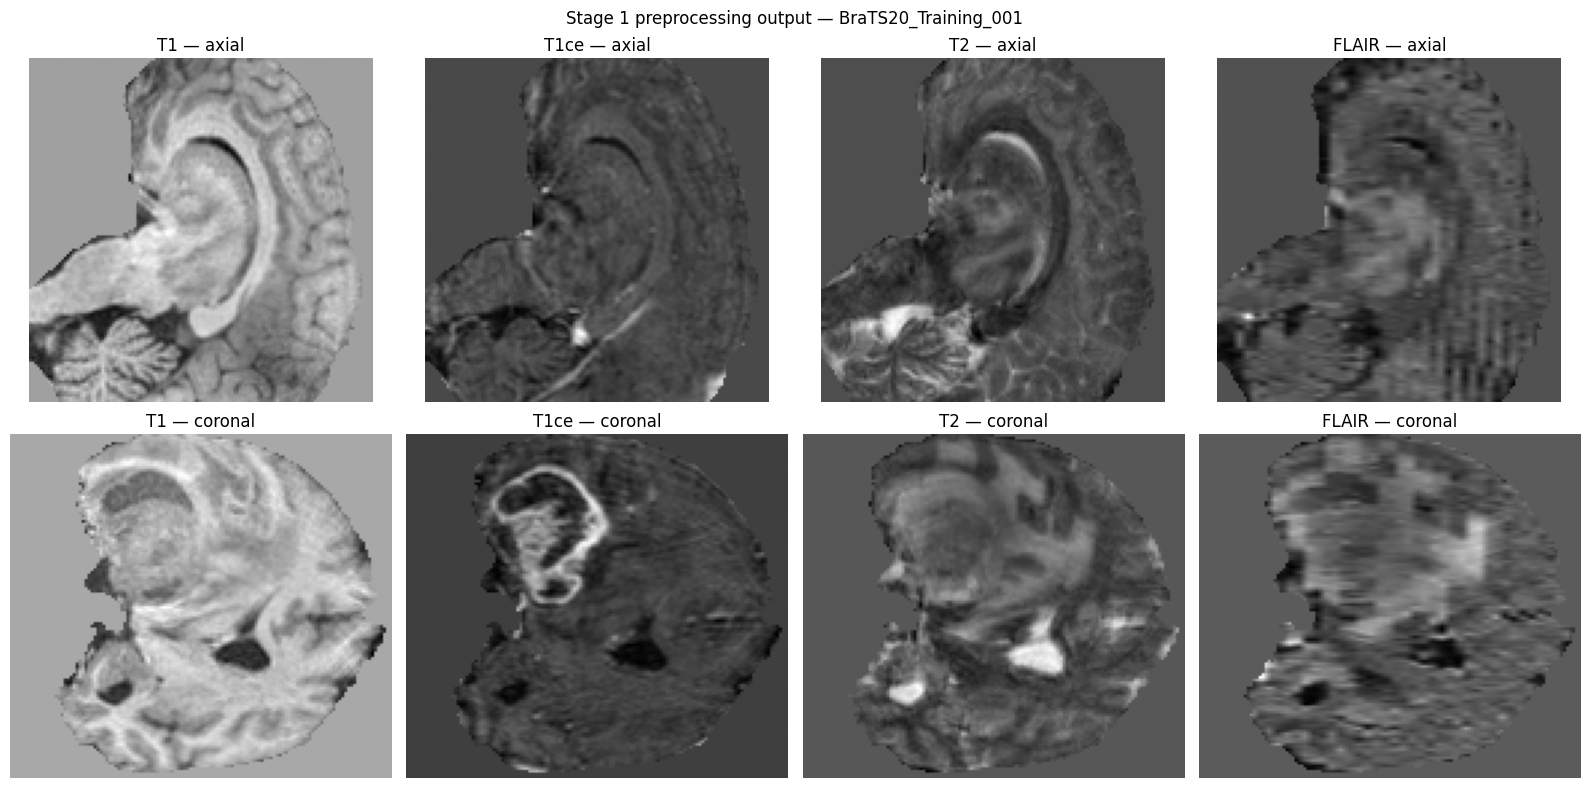

In [8]:
# Triptych: each modality, axial + coronal mid-slice
import matplotlib.pyplot as plt
import numpy as np

vol = out.volume
modalities = ["T1", "T1ce", "T2", "FLAIR"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, m in enumerate(modalities):
    D, H, W = vol.shape[1:]
    axes[0, i].imshow(vol[i, D // 2], cmap="gray")
    axes[0, i].set_title(f"{m} — axial")
    axes[0, i].axis("off")
    axes[1, i].imshow(vol[i, :, H // 2, :], cmap="gray", aspect="auto")
    axes[1, i].set_title(f"{m} — coronal")
    axes[1, i].axis("off")
fig.suptitle(f"Stage 1 preprocessing output — {subject_id}")
plt.tight_layout()
plt.savefig("/kaggle/working/preprocessing_triptych.png", dpi=120, bbox_inches="tight")
plt.show()

## 5 · Synthetic report generated from the segmentation mask

Demonstrates the templated VASARI feature extractor — same code that produces the synthetic warmup benchmark.


In [9]:
from neuroval3d.data import SyntheticReportGenerator
import nibabel as nib, numpy as np

seg = np.asarray(nib.load(seg_path).dataobj, dtype=np.int16)
synth = SyntheticReportGenerator().from_mask(seg, voxel_volume_mm3=1.0)
print("=== Generated radiology report from the segmentation ===")
print(synth.text)
print("\n=== Extracted VASARI features ===")
for k, v in synth.vasari_features.items():
    print(f"  {k:25s}: {v}")


=== Generated radiology report from the segmentation ===
FINDINGS:
- There is a 10.9 cm intra-axial lesion centred in the right occipital lobe.
- The lesion demonstrates moderate enhancement on post-contrast T1 imaging.
- Surrounding T2/FLAIR hyperintensity reflects marked vasogenic oedema.
- Central low-T1 / high-T2 signal is consistent with moderate necrosis.
- Additional satellite lesions are noted, indicating multifocal disease.
- The mass extends across the midline.
- There is no evidence of acute hemorrhage on susceptibility imaging.
- Diffusion-weighted imaging does not show restricted diffusion.

IMPRESSION:
10.9 cm moderate intra-axial mass in the right occipital lobe with marked surrounding oedema. Findings are most consistent with a high-grade glial neoplasm; recommend correlation with clinical context and consideration of histopathological confirmation.

=== Extracted VASARI features ===
  tumor_present            : yes
  side                     : right
  region           

## 6 · The headline chart — NeuroVal-3D vs baselines


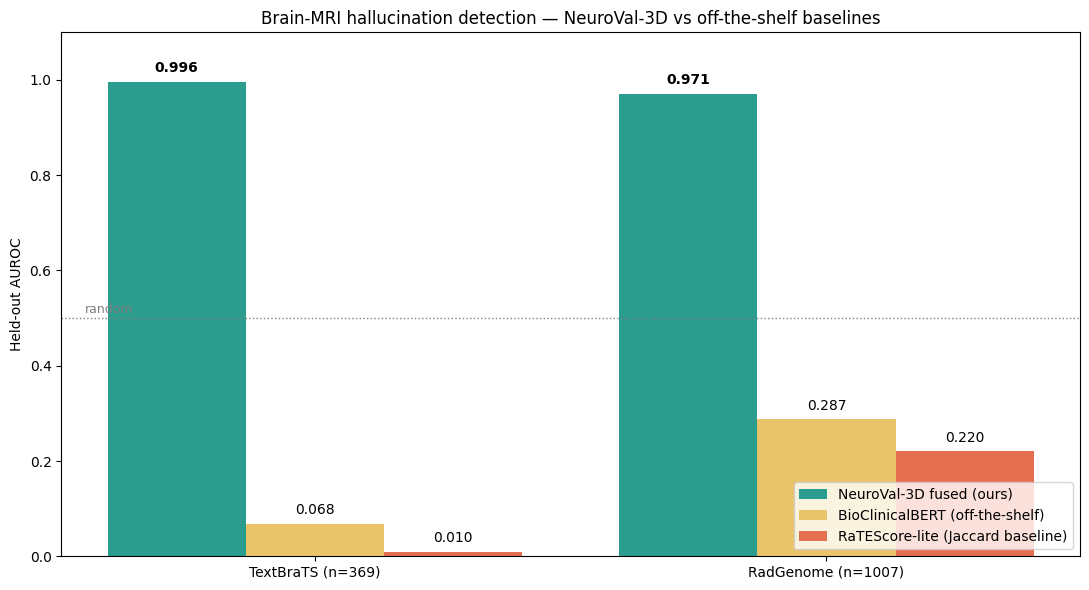

In [10]:
import matplotlib.pyplot as plt
import numpy as np

datasets = ["TextBraTS (n=369)", "RadGenome (n=1007)"]
ours = [
    result_tb.auroc_overall.get("fusion", 0.0),
    result_rg.auroc_overall.get("fusion", 0.0),
]
bioclin = [
    result_tb.auroc_overall.get("semantic", 0.0),
    result_rg.auroc_overall.get("semantic", 0.0),
]
ratescore = [
    result_tb.auroc_overall.get("ratescore_lite (baseline)", 0.0),
    result_rg.auroc_overall.get("ratescore_lite (baseline)", 0.0),
]

x = np.arange(len(datasets))
width = 0.27
fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(x - width, ours,      width, label="NeuroVal-3D fused (ours)", color="#2a9d8f")
ax.bar(x,         bioclin,   width, label="BioClinicalBERT (off-the-shelf)", color="#e9c46a")
ax.bar(x + width, ratescore, width, label="RaTEScore-lite (Jaccard baseline)", color="#e76f51")
for i, v in enumerate(ours):
    ax.text(x[i] - width, v + 0.02, f"{v:.3f}", ha="center", fontsize=10, fontweight="bold")
for i, v in enumerate(bioclin):
    ax.text(x[i], v + 0.02, f"{v:.3f}", ha="center", fontsize=10)
for i, v in enumerate(ratescore):
    ax.text(x[i] + width, v + 0.02, f"{v:.3f}", ha="center", fontsize=10)

ax.axhline(0.5, ls=":", color="gray", lw=1)
ax.text(-0.45, 0.51, "random", color="gray", fontsize=9)
ax.set_ylabel("Held-out AUROC")
ax.set_title("Brain-MRI hallucination detection — NeuroVal-3D vs off-the-shelf baselines")
ax.set_xticks(x)
ax.set_xticklabels(datasets)
ax.legend(loc="lower right")
ax.set_ylim([0, 1.10])
plt.tight_layout()
plt.savefig("/kaggle/working/auroc_bar_chart.png", dpi=120, bbox_inches="tight")
plt.show()


## 7 · Diagnostic plots — ROC, PR, confusion matrix, score distributions, per-op heatmap

Loads the per-record scores (saved by `run_benchmark`) and plots the standard set of binary-classification diagnostics for both datasets.


In [11]:
# Load per-record scores from both held-out runs into pandas DataFrames
import json
from pathlib import Path
import pandas as pd

def load_scores(run_id: str) -> pd.DataFrame:
    p = Path(f"/kaggle/working/neuroval3d/outputs/results/{run_id}/scores.jsonl")
    rows = [json.loads(l) for l in open(p, encoding="utf-8") if l.strip()]
    return pd.DataFrame(rows)

df_tb = load_scores(result_tb.run_id)
df_rg = load_scores(result_rg.run_id)
for name, df in [("TextBraTS", df_tb), ("RadGenome", df_rg)]:
    splits = df["split"].value_counts().to_dict()
    pos = (df[df.split == "test"]["label"] == 1).sum()
    neg = (df[df.split == "test"]["label"] == 0).sum()
    print(f"{name}: {len(df)} total, splits={splits}, test positives={pos}, test negatives={neg}")


TextBraTS: 1829 total, splits={'train': 1278, 'test': 551}, test positives=111, test negatives=440
RadGenome: 4891 total, splits={'train': 3419, 'test': 1472}, test positives=302, test negatives=1170


### 7.1 ROC curves — fusion vs each axis vs baselines (held-out test split)


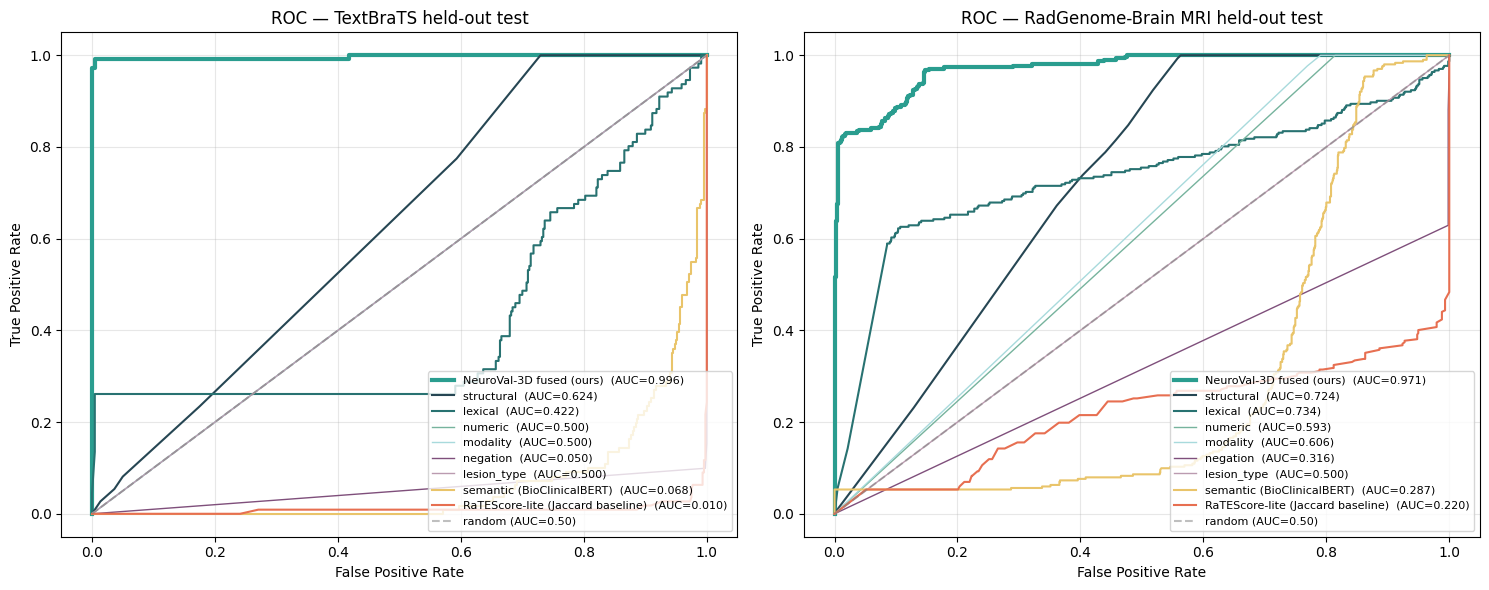

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

VALIDATOR_STYLE = [
    ("fused",          "NeuroVal-3D fused (ours)",       "#2a9d8f", 3.0),
    ("structural",     "structural",                      "#264653", 1.5),
    ("lexical",        "lexical",                         "#287271", 1.5),
    ("numeric",        "numeric",                         "#76b39d", 1.0),
    ("modality",       "modality",                        "#a8dadc", 1.0),
    ("negation",       "negation",                        "#7f4f7b", 1.0),
    ("lesion_type",    "lesion_type",                     "#bb9bb0", 1.0),
    ("semantic",       "semantic (BioClinicalBERT)",      "#e9c46a", 1.5),
    ("ratescore_lite", "RaTEScore-lite (Jaccard baseline)", "#e76f51", 1.5),
]

def plot_roc(df: pd.DataFrame, title: str, ax) -> None:
    test = df[df.split == "test"]
    if len(test) == 0:
        ax.text(0.5, 0.5, "no test rows", ha="center", transform=ax.transAxes); return
    for col, label, color, lw in VALIDATOR_STYLE:
        if col not in test.columns:
            continue
        fpr, tpr, _ = roc_curve(test["label"], test[col])
        ax.plot(fpr, tpr, label=f"{label}  (AUC={auc(fpr, tpr):.3f})", color=color, linewidth=lw)
    ax.plot([0, 1], [0, 1], "--", color="gray", alpha=0.5, label="random (AUC=0.50)")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(alpha=0.3)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_roc(df_tb, "ROC — TextBraTS held-out test", axes[0])
plot_roc(df_rg, "ROC — RadGenome-Brain MRI held-out test", axes[1])
plt.tight_layout()
plt.savefig("/kaggle/working/roc_curves.png", dpi=140, bbox_inches="tight")
plt.show()


### 7.2 Precision-Recall curves

Better than ROC when the classes are imbalanced (we have ~5× more perturbed records than clean ones).


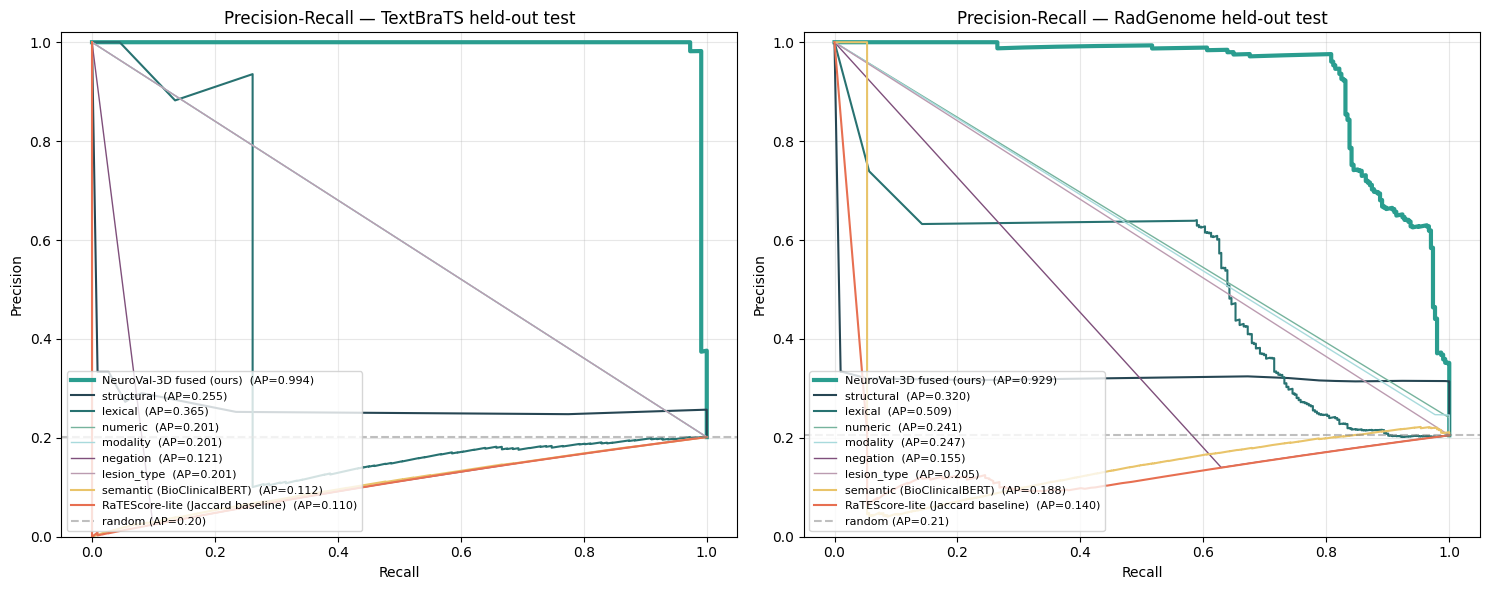

In [13]:
from sklearn.metrics import precision_recall_curve, average_precision_score

def plot_pr(df: pd.DataFrame, title: str, ax) -> None:
    test = df[df.split == "test"]
    if len(test) == 0:
        ax.text(0.5, 0.5, "no test rows", ha="center", transform=ax.transAxes); return
    base_rate = test["label"].mean()
    for col, label, color, lw in VALIDATOR_STYLE:
        if col not in test.columns:
            continue
        precision, recall, _ = precision_recall_curve(test["label"], test[col])
        ap = average_precision_score(test["label"], test[col])
        ax.plot(recall, precision, label=f"{label}  (AP={ap:.3f})", color=color, linewidth=lw)
    ax.axhline(base_rate, ls="--", color="gray", alpha=0.5, label=f"random (AP={base_rate:.2f})")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title(title)
    ax.legend(loc="lower left", fontsize=8)
    ax.grid(alpha=0.3)
    ax.set_ylim([0, 1.02])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_pr(df_tb, "Precision-Recall — TextBraTS held-out test", axes[0])
plot_pr(df_rg, "Precision-Recall — RadGenome held-out test", axes[1])
plt.tight_layout()
plt.savefig("/kaggle/working/pr_curves.png", dpi=140, bbox_inches="tight")
plt.show()


### 7.3 Confusion matrices @ threshold 0.5

How the fusion validator labels each held-out test record at the default 0.5 threshold. Includes accuracy, precision, recall, F1.


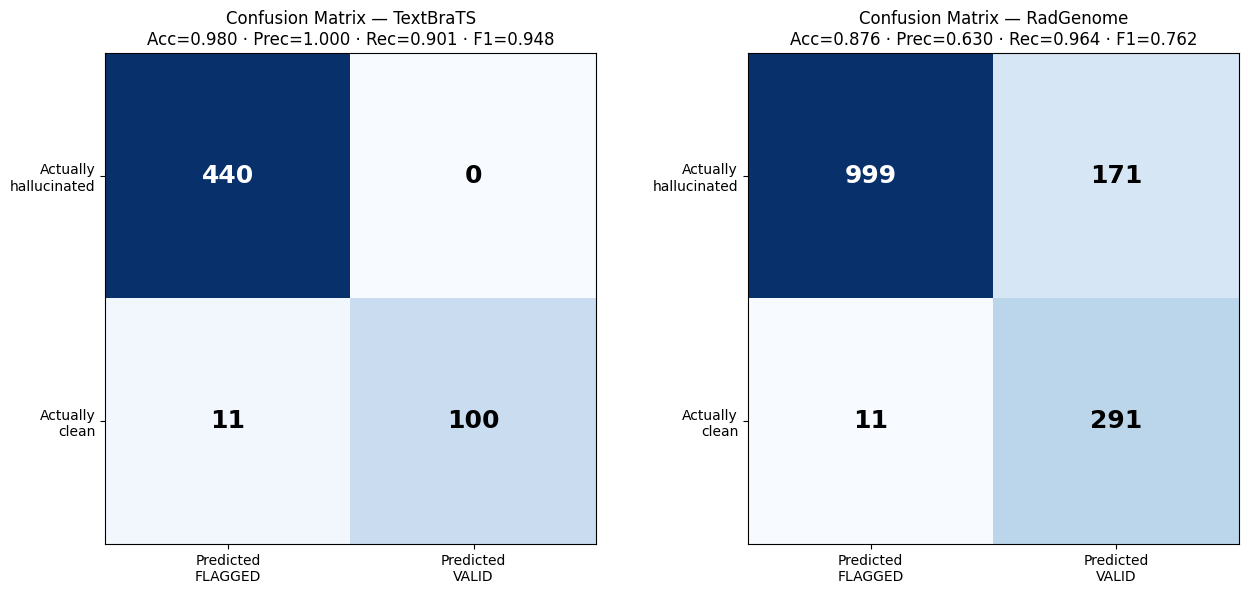

In [14]:
from sklearn.metrics import confusion_matrix

def plot_cm(df: pd.DataFrame, title: str, ax, threshold: float = 0.5) -> None:
    test = df[df.split == "test"]
    if len(test) == 0:
        ax.text(0.5, 0.5, "no test rows", ha="center", transform=ax.transAxes); return
    y_true = test["label"].values
    y_pred = (test["fused"] >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    acc = (tp + tn) / max(tp + tn + fp + fn, 1)
    prec = tp / max(tp + fp, 1)
    rec = tp / max(tp + fn, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-9)

    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Predicted\nFLAGGED", "Predicted\nVALID"])
    ax.set_yticklabels(["Actually\nhallucinated", "Actually\nclean"])
    for i in range(2):
        for j in range(2):
            color = "white" if cm[i, j] > cm.max() * 0.5 else "black"
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color=color, fontsize=18, fontweight="bold")
    ax.set_title(f"{title}\nAcc={acc:.3f} · Prec={prec:.3f} · Rec={rec:.3f} · F1={f1:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
plot_cm(df_tb, "Confusion Matrix — TextBraTS", axes[0])
plot_cm(df_rg, "Confusion Matrix — RadGenome", axes[1])
plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrices.png", dpi=140, bbox_inches="tight")
plt.show()


### 7.4 Score distribution (clean vs hallucinated, held-out test)

Visualises separability — the further apart the two histograms, the easier the validator's job.


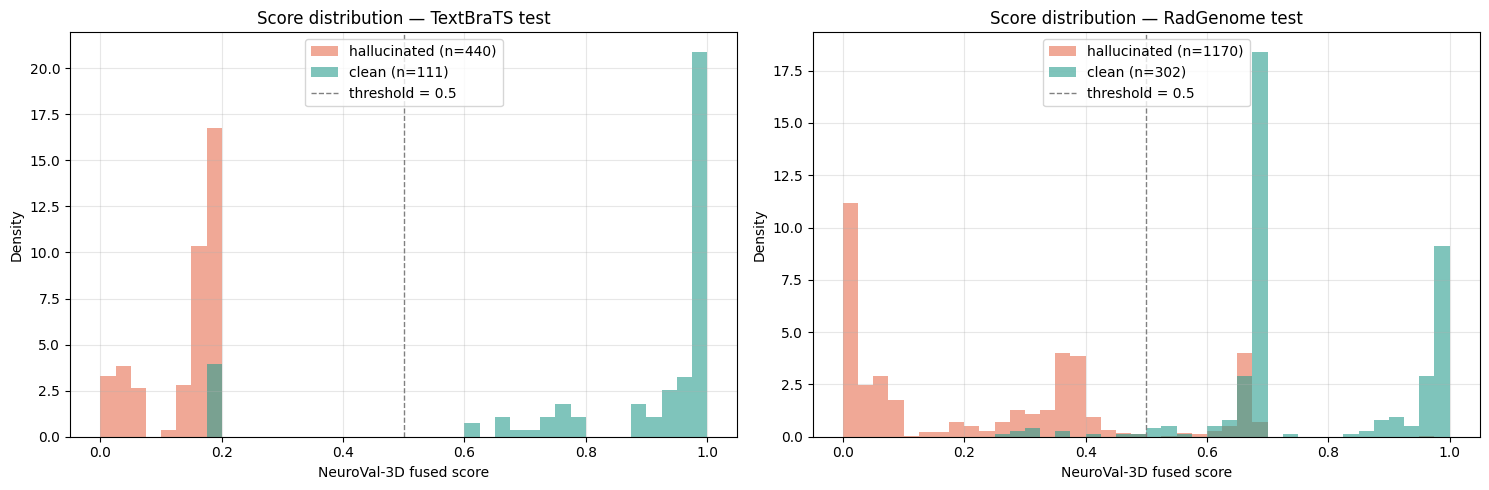

In [15]:
import numpy as np

def plot_dist(df: pd.DataFrame, title: str, ax) -> None:
    test = df[df.split == "test"]
    if len(test) == 0:
        ax.text(0.5, 0.5, "no test rows", ha="center", transform=ax.transAxes); return
    bins = np.linspace(0, 1, 41)
    pos = test[test.label == 1]["fused"]
    neg = test[test.label == 0]["fused"]
    ax.hist(neg, bins=bins, alpha=0.6, color="#e76f51", label=f"hallucinated (n={len(neg)})", density=True)
    ax.hist(pos, bins=bins, alpha=0.6, color="#2a9d8f", label=f"clean (n={len(pos)})", density=True)
    ax.axvline(0.5, ls="--", color="gray", lw=1, label="threshold = 0.5")
    ax.set_xlabel("NeuroVal-3D fused score")
    ax.set_ylabel("Density")
    ax.set_title(title)
    ax.legend(loc="upper center")
    ax.grid(alpha=0.3)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_dist(df_tb, "Score distribution — TextBraTS test", axes[0])
plot_dist(df_rg, "Score distribution — RadGenome test", axes[1])
plt.tight_layout()
plt.savefig("/kaggle/working/score_distributions.png", dpi=140, bbox_inches="tight")
plt.show()


### 7.5 Per-op AUROC heatmap (validator × perturbation type)

Reads the test-set AUROC for every (validator, perturbation operation) combination. Tells you which validator catches which error class. Each axis should be near-perfect on its specialty.


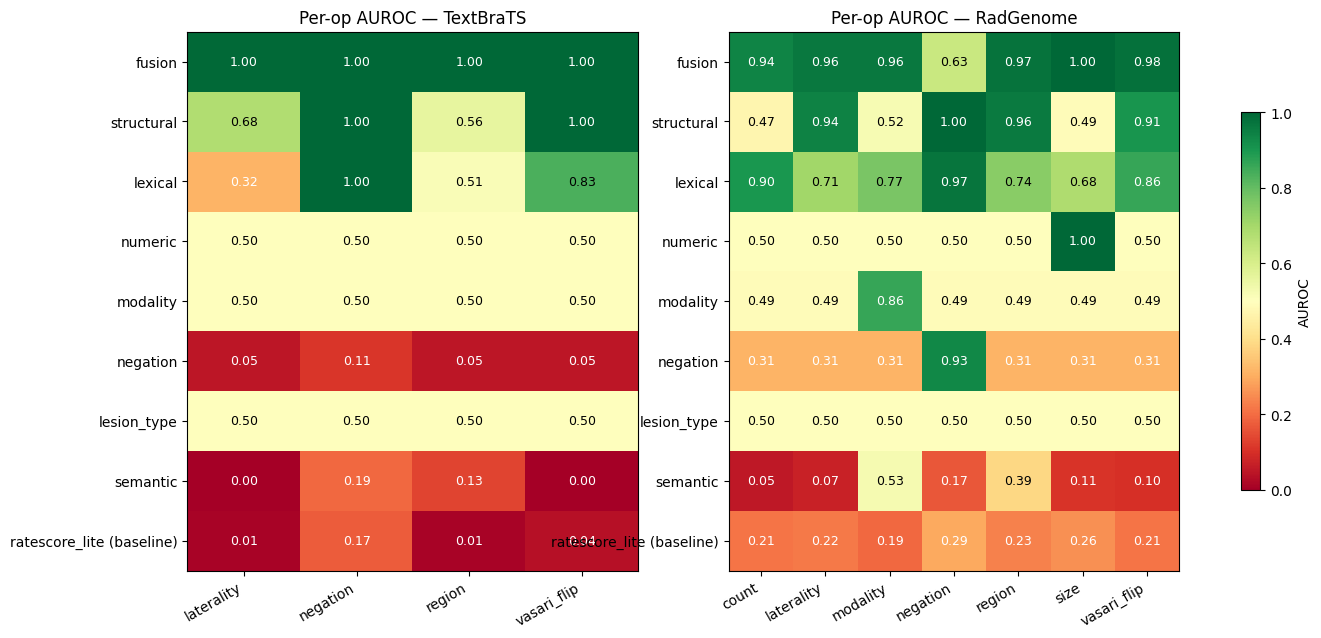

In [16]:
VALIDATOR_ORDER = [
    "fusion", "structural", "lexical", "numeric", "modality",
    "negation", "lesion_type", "semantic", "ratescore_lite (baseline)",
]

def per_op_heatmap(result, title: str, ax):
    by_op = result.auroc_by_op
    ops = sorted(by_op.keys())
    M = np.full((len(VALIDATOR_ORDER), len(ops)), np.nan)
    for i, v in enumerate(VALIDATOR_ORDER):
        for j, op in enumerate(ops):
            if v in by_op[op]:
                M[i, j] = by_op[op][v]
    im = ax.imshow(M, cmap="RdYlGn", vmin=0.0, vmax=1.0, aspect="auto")
    ax.set_xticks(range(len(ops)))
    ax.set_xticklabels(ops, rotation=30, ha="right")
    ax.set_yticks(range(len(VALIDATOR_ORDER)))
    ax.set_yticklabels(VALIDATOR_ORDER)
    for i in range(len(VALIDATOR_ORDER)):
        for j in range(len(ops)):
            v = M[i, j]
            if not np.isnan(v):
                color = "white" if (v < 0.35 or v > 0.85) else "black"
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color=color)
    ax.set_title(title)
    return im

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
im_a = per_op_heatmap(result_tb, "Per-op AUROC — TextBraTS", axes[0])
im_b = per_op_heatmap(result_rg, "Per-op AUROC — RadGenome", axes[1])
fig.colorbar(im_b, ax=axes, location="right", shrink=0.7, label="AUROC")
plt.savefig("/kaggle/working/per_op_heatmap.png", dpi=140, bbox_inches="tight")
plt.show()


### 7.6 Train vs Test AUROC — the analog of train/test loss

**Why no `loss curves`?** The fusion validator is a single sklearn `LogisticRegression` fit — closed-form on a small sample, not an iterative gradient-descent loop. There's no per-epoch loss to plot. The right diagnostic for overfit detection here is **gap between train AUROC and held-out test AUROC** — if the fusion is memorising, train AUROC ≫ test AUROC. We want them close.

When we train the BART or Llama-3 decoder in Phase 2, that's where proper per-epoch loss curves show up.


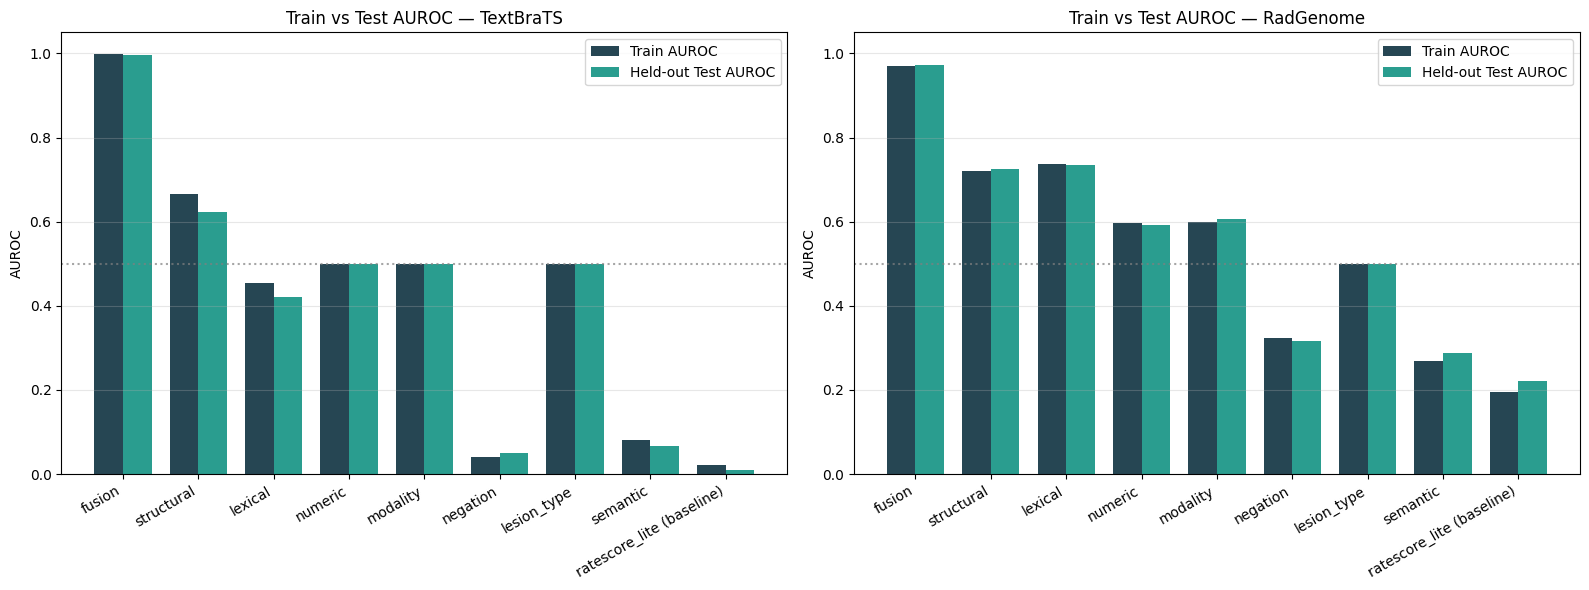


Fusion train→test gap (should be near zero — confirms no overfit):
  TextBraTS   : train=0.9990, test=0.9962, gap=+0.0028
  RadGenome   : train=0.9698, test=0.9714, gap=-0.0016


In [17]:
def plot_train_vs_test(result, title: str, ax) -> None:
    train = [result.auroc_train.get(v, np.nan) for v in VALIDATOR_ORDER]
    test  = [result.auroc_overall.get(v, np.nan) for v in VALIDATOR_ORDER]
    x = np.arange(len(VALIDATOR_ORDER))
    width = 0.38
    ax.bar(x - width/2, train, width, label="Train AUROC", color="#264653")
    ax.bar(x + width/2, test,  width, label="Held-out Test AUROC", color="#2a9d8f")
    ax.axhline(0.5, ls=":", color="gray", alpha=0.7)
    ax.set_xticks(x)
    ax.set_xticklabels(VALIDATOR_ORDER, rotation=30, ha="right")
    ax.set_ylabel("AUROC")
    ax.set_title(title)
    ax.set_ylim([0, 1.05])
    ax.legend()
    ax.grid(alpha=0.3, axis="y")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_train_vs_test(result_tb, "Train vs Test AUROC — TextBraTS", axes[0])
plot_train_vs_test(result_rg, "Train vs Test AUROC — RadGenome", axes[1])
plt.tight_layout()
plt.savefig("/kaggle/working/train_vs_test.png", dpi=140, bbox_inches="tight")
plt.show()

# Print numeric gaps for the paper
print("\nFusion train→test gap (should be near zero — confirms no overfit):")
for name, r in [("TextBraTS", result_tb), ("RadGenome", result_rg)]:
    gap = r.auroc_train.get("fusion", float("nan")) - r.auroc_overall.get("fusion", float("nan"))
    print(f"  {name:12s}: train={r.auroc_train.get('fusion', float('nan')):.4f}, test={r.auroc_overall.get('fusion', float('nan')):.4f}, gap={gap:+.4f}")


## 8 · Where the artefacts landed

All saved under `/kaggle/working/`:

- `preprocessing_triptych.png` — Stage 1 output for one BraTS volume
- `auroc_bar_chart.png` — headline NeuroVal-3D vs baselines
- `roc_curves.png` — ROC for fusion + each axis on both datasets
- `pr_curves.png` — Precision-Recall curves
- `confusion_matrices.png` — at threshold 0.5 with Acc/Prec/Rec/F1
- `score_distributions.png` — clean vs hallucinated histograms
- `per_op_heatmap.png` — validator × perturbation-op heatmap
- `train_vs_test.png` — train/test AUROC bars (no overfit check)

Per-run AUROC tables + raw scores under `/kaggle/working/neuroval3d/outputs/results/`.

## 9 · What's next

- **Cross-dataset transfer** (TextBraTS → RadGenome and reverse) — run `python scripts/run_cross_only.py` for the transfer numbers (~2 hr more).
- **Phase 2 proper**: train a small report decoder (BART-base) using the preprocessed volumes from Stage 1 above. Use the resulting generated reports as the test corpus for NeuroVal-3D — closes the generator-validator loop. **This is where real per-epoch train/test loss curves live.**
- **Negation axis improvement** (round 6) — fusion negation AUROC is the weakest spot at 0.63 on RadGenome. Integrate `negspaCy` to lift it past 0.85.
